This notebook is for exploring the dataset, finding problems that needs to be fixed. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_excel('../Data/raw/online_retail_II.xlsx')
df.shape

(525461, 8)

Only reading one sheet, file has two

In [3]:
sheet = pd.read_excel('../Data/raw/online_retail_II.xlsx', sheet_name =None)

In [4]:
sheet.keys()

dict_keys(['Year 2009-2010', 'Year 2010-2011'])

In [5]:
df = pd.concat(sheet.values(), ignore_index = True)
df.shape

(1067371, 8)

In [6]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [8]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


negative values = return/canellations
checking to see how much of the data is returns/cansellations


In [9]:
neg = df[df['Quantity'] < 0]
neg.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [10]:
is_cancelled = df['Invoice'].astype(str).str.startswith('C')
print(is_cancelled.sum())

19494


The table under seems to be the stores own regulation of products, maybe broken or lost products in storage. 

In [11]:
df[(df["Quantity"] < 0) & ~is_cancelled].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


For now using the date from sales, not returns. Maybe returns could be good nect project. 

In [12]:
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()


In [13]:
df['Revenue'] = df['Quantity']*df['Price']

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 1041671 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1041671 non-null  object        
 1   StockCode    1041671 non-null  object        
 2   Description  1041671 non-null  object        
 3   Quantity     1041671 non-null  int64         
 4   InvoiceDate  1041671 non-null  datetime64[us]
 5   Price        1041671 non-null  float64       
 6   Customer ID  805549 non-null   float64       
 7   Country      1041671 non-null  str           
 8   Revenue      1041671 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 79.5+ MB


In [15]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID,Revenue
count,1.041671e+06,1041671,1.041671e+06,805549.000000,1.041671e+06
mean,1.096345e+01,2011-01-03 16:31:26.403269,4.077038e+00,15331.954970,2.013397e+01
min,1.000000e+00,2009-12-01 07:45:00,1.000000e-03,12346.000000,1.000000e-03
25%,1.000000e+00,2010-07-12 10:26:00,1.250000e+00,13982.000000,3.900000e+00
50%,3.000000e+00,2010-12-07 15:33:00,2.100000e+00,15271.000000,9.960000e+00
75%,1.000000e+01,2011-07-24 12:05:00,4.130000e+00,16805.000000,1.770000e+01
max,8.099500e+04,2011-12-09 12:50:00,2.511109e+04,18287.000000,1.684696e+05
std,1.265149e+02,NaN,5.144898e+01,1696.737039,2.031167e+02


<Axes: xlabel='InvoiceDate'>

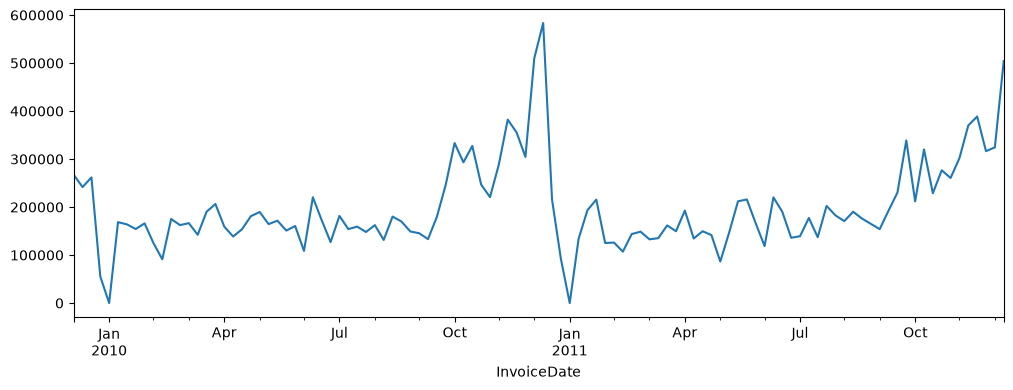

In [16]:
df.set_index('InvoiceDate')["Revenue"].resample("W").sum().plot(figsize=(12, 4))


In [17]:
df['Weekday'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

<Axes: xlabel='Hour', ylabel='Weekday'>

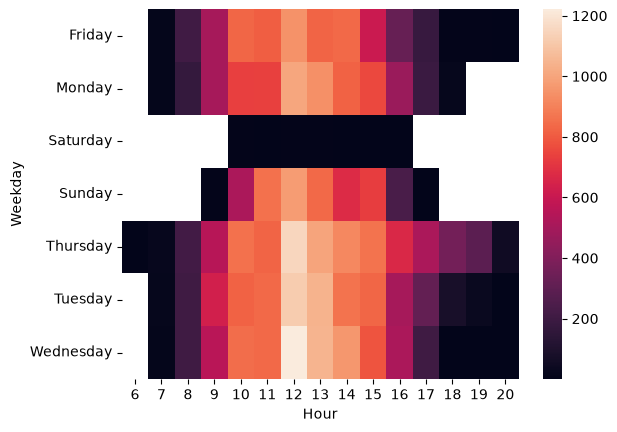

In [18]:
pivot = df.pivot_table(index="Weekday", columns="Hour", values="Invoice", aggfunc="nunique")
sns.heatmap(pivot)

seems to be more shopping between 10 and 15, and no shopping on saturday

<Axes: xlabel='Quantity', ylabel='Count'>

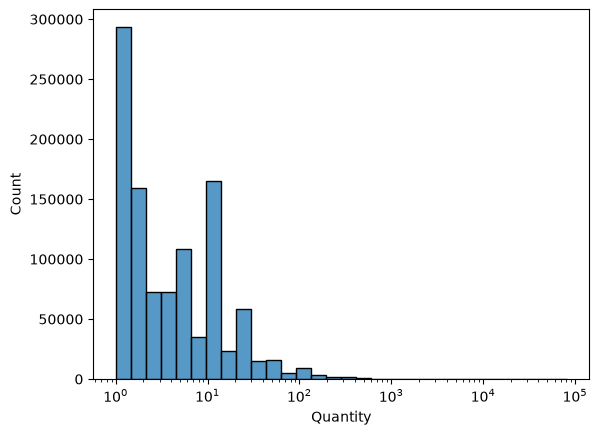

In [19]:
sns.histplot(df['Quantity'], log_scale= True, bins = 30)

<Axes: xlabel='Price', ylabel='Count'>

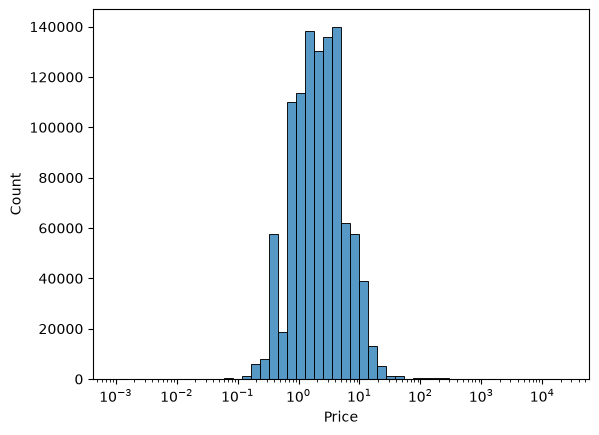

In [20]:
sns.histplot(df['Price'], log_scale = True, bins = 50)

so most product are pretty cheap

In [21]:
df["Price"].describe(percentiles=[.5, .9, .99, .999])

count    1.041671e+06
mean     4.077038e+00
std      5.144898e+01
min      1.000000e-03
50%      2.100000e+00
90%      7.950000e+00
99%      1.800000e+01
99.9%    1.592760e+02
max      2.511109e+04
Name: Price, dtype: float64

seems like 50 persent of the rows are less than 2.1 and 90 percent less that 7.59, checking for the extreme values. 

In [22]:
df.nlargest(40, "Price")


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,25111.09,Thursday,16
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33,Tuesday,15
540478,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33,Tuesday,15
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06,Friday,14
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom,10953.50,Tuesday,15
135015,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,NaN,United Kingdom,10953.50,Tuesday,15
342147,522796,M,Manual,1,2010-09-16 15:12:00,10468.80,NaN,United Kingdom,10468.80,Thursday,15
358639,524159,M,Manual,1,2010-09-27 16:12:00,10468.80,14063.0,United Kingdom,10468.80,Monday,16
372834,525399,M,Manual,1,2010-10-05 11:49:00,10468.80,NaN,United Kingdom,10468.80,Tuesday,11
74356,496115,M,Manual,1,2010-01-29 11:04:00,8985.60,17949.0,United Kingdom,8985.60,Friday,11


do far, M,adjust, Amazonfee, Post and B ar not products will remove.

In [23]:
df[df["StockCode"].str.len() < 5]["StockCode"].value_counts()

StockCode
POST    1886
DOT     1436
M        877
C2       272
PADS      17
m          5
D          5
S          3
B          1
Name: count, dtype: int64

In [24]:
code = df["StockCode"].astype(str)
code[~code.str.match(r"^\d{5}")].value_counts()

StockCode
POST            1886
DOT             1436
M                877
C2               272
ADJUST            36
BANK CHARGES      35
DCGS0058          30
gift_0001_20      26
gift_0001_30      24
DCGSSGIRL         23
DCGSSBOY          21
PADS              17
DCGS0076          15
gift_0001_10      14
DCGS0003          13
TEST001            9
gift_0001_50       6
m                  5
DCGS0069           5
D                  5
gift_0001_40       5
DCGS0004           4
AMAZONFEE          4
DCGS0072           3
S                  3
ADJUST2            3
DCGS0068           2
DCGS0066N          2
DCGS0070           2
SP1002             2
gift_0001_80       1
DCGS0044           1
TEST002            1
DCGS0075           1
DCGS0041           1
gift_0001_70       1
DCGS0037           1
DCGS0062           1
B                  1
Name: count, dtype: int64

seems to be many type of non products, will check them

In [25]:

df[df["StockCode"] == "B"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06,Friday,14


In [26]:
df[df["StockCode"] == "DCGS0062"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
414064,528952,DCGS0062,ROAD-RAGE CAR FRESHENER,1,2010-10-25 16:57:00,2.51,NaN,United Kingdom,2.51,Monday,16


In [27]:
df[df["StockCode"].astype(str).str.startswith("DCGS")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
2377,489597,DCGS0058,MISO PRETTY GUM,1,2009-12-01 14:28:00,0.83,NaN,United Kingdom,0.83,Tuesday,14
2378,489597,DCGS0068,DOGS NIGHT COLLAR,1,2009-12-01 14:28:00,8.65,NaN,United Kingdom,8.65,Tuesday,14
8371,490074,DCGS0004,HAYNES CAMPER SHOULDER BAG,1,2009-12-03 14:39:00,17.35,NaN,United Kingdom,17.35,Thursday,14
8372,490074,DCGS0058,MISO PRETTY GUM,1,2009-12-03 14:39:00,0.83,NaN,United Kingdom,0.83,Thursday,14
8373,490074,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT,1,2009-12-03 14:39:00,16.48,NaN,United Kingdom,16.48,Thursday,14
...,...,...,...,...,...,...,...,...,...,...,...
843773,564825,DCGSSGIRL,GIRLS PARTY BAG,1,2011-08-30 12:26:00,3.29,NaN,United Kingdom,3.29,Tuesday,12
891427,568716,DCGSSBOY,BOYS PARTY BAG,2,2011-09-28 16:13:00,3.29,NaN,United Kingdom,6.58,Wednesday,16
933664,571931,DCGSSGIRL,GIRLS PARTY BAG,1,2011-10-19 16:59:00,3.29,NaN,United Kingdom,3.29,Wednesday,16
1000063,576840,DCGSSGIRL,GIRLS PARTY BAG,1,2011-11-16 15:23:00,3.29,NaN,United Kingdom,3.29,Wednesday,15


DCGS stock code are real products, will keep them.

In [28]:
df[df["StockCode"].astype(str).str.startswith("gift")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
31079,491969,gift_0001_80,Dotcomgiftshop Gift Voucher £80.00,1,2009-12-14 17:57:00,69.56,NaN,United Kingdom,69.56,Monday,17
32048,491971,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,2,2009-12-14 18:37:00,17.39,NaN,United Kingdom,34.78,Monday,18
40904,492782,gift_0001_10,Dotcomgiftshop Gift Voucher £10.00,1,2009-12-18 17:06:00,8.69,NaN,United Kingdom,8.69,Friday,17
40905,492782,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,1,2009-12-18 17:06:00,17.39,NaN,United Kingdom,17.39,Friday,17
41263,492783,gift_0001_50,Dotcomgiftshop Gift Voucher £50.00,1,2009-12-18 17:15:00,43.48,NaN,United Kingdom,43.48,Friday,17
...,...,...,...,...,...,...,...,...,...,...,...
842903,564760,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,1,2011-08-30 10:47:00,25.00,NaN,United Kingdom,25.00,Tuesday,10
845901,564974,gift_0001_10,Dotcomgiftshop Gift Voucher £10.00,2,2011-08-31 15:32:00,8.33,NaN,United Kingdom,16.66,Wednesday,15
847625,565231,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,1,2011-09-02 09:26:00,25.00,NaN,United Kingdom,25.00,Friday,9
956810,573585,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,1,2011-10-31 14:41:00,16.67,NaN,United Kingdom,16.67,Monday,14


gift vouchers, i will remove them, might be a fun prosject for another time. Observing that all prices are before tax.

In [29]:
df[df["StockCode"].astype(str).str.startswith("TEST")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
27994,491725,TEST001,This is a test product.,10,2009-12-14 08:34:00,4.5,12346.0,United Kingdom,45.0,Monday,8
28251,491742,TEST001,This is a test product.,5,2009-12-14 11:00:00,4.5,12346.0,United Kingdom,22.5,Monday,11
28254,491744,TEST001,This is a test product.,5,2009-12-14 11:02:00,4.5,12346.0,United Kingdom,22.5,Monday,11
39398,492718,TEST001,This is a test product.,5,2009-12-18 10:47:00,4.5,12346.0,United Kingdom,22.5,Friday,10
39411,492722,TEST002,This is a test product.,1,2009-12-18 10:55:00,1.0,12346.0,United Kingdom,1.0,Friday,10
45228,493410,TEST001,This is a test product.,5,2010-01-04 09:24:00,4.5,12346.0,United Kingdom,22.5,Monday,9
45230,493412,TEST001,This is a test product.,5,2010-01-04 09:53:00,4.5,12346.0,United Kingdom,22.5,Monday,9
56117,494450,TEST001,This is a test product.,5,2010-01-14 13:50:00,4.5,12346.0,United Kingdom,22.5,Thursday,13
66084,495295,TEST001,This is a test product.,5,2010-01-22 13:30:00,4.5,12346.0,United Kingdom,22.5,Friday,13
156017,504188,TEST001,This is a test product.,5,2010-04-12 09:52:00,4.5,16454.0,United Kingdom,22.5,Monday,9


test products - remove

In [30]:
df[df["StockCode"].astype(str).str.startswith("SP")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
377066,525772,SP1002,KID'S CHALKBOARD/EASEL,1,2010-10-07 11:12:00,2.95,12748.0,United Kingdom,2.95,Thursday,11
377387,525837,SP1002,KID'S CHALKBOARD/EASEL,4,2010-10-07 12:23:00,2.95,17841.0,United Kingdom,11.80,Thursday,12


starting with SP -keep

In [31]:
df[df["StockCode"].astype(str) =="D"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
160443,504700,D,Discount,1,2010-04-15 18:08:00,57.63,17032.0,United Kingdom,57.63,Thursday,18
212633,509979,D,Discount,1,2010-05-26 14:07:00,101.99,12843.0,United Kingdom,101.99,Wednesday,14
312285,519808,D,Discount,192,2010-08-20 12:50:00,1.00,16422.0,United Kingdom,192.00,Friday,12
494226,535657,D,Discount,1,2010-11-28 11:20:00,13.98,14527.0,United Kingdom,13.98,Sunday,11
501237,536158,D,Discount,1,2010-11-30 11:57:00,32.29,13634.0,United Kingdom,32.29,Tuesday,11


In [32]:
df[df["StockCode"].astype(str) =="m"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
96608,498492,m,Manual,1,2010-02-19 10:56:00,2.55,NaN,United Kingdom,2.55,Friday,10
96609,498492,m,Manual,1,2010-02-19 10:56:00,3.40,NaN,United Kingdom,3.40,Friday,10
157226,504396,m,Manual,1,2010-04-13 11:45:00,4.00,NaN,United Kingdom,4.00,Tuesday,11
228780,511509,m,Manual,1,2010-06-08 15:26:00,2.55,NaN,United Kingdom,2.55,Tuesday,15
565844,539736,m,Manual,1,2010-12-21 15:18:00,2.55,NaN,United Kingdom,2.55,Tuesday,15


In [33]:
df[df["StockCode"].astype(str) =="PADS"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-19 17:04:00,0.001,16705.0,United Kingdom,0.001,Tuesday,17
74731,496222,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-01-29 13:53:00,0.001,13583.0,United Kingdom,0.001,Friday,13
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-01 15:38:00,0.001,17350.0,United Kingdom,0.001,Monday,15
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-03 11:58:00,0.001,13408.0,United Kingdom,0.001,Wednesday,11
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-15 10:47:00,0.001,13408.0,United Kingdom,0.001,Monday,10
97716,498562,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-21 12:03:00,0.001,15182.0,United Kingdom,0.001,Sunday,12
101718,499056,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-24 13:46:00,0.001,13765.0,United Kingdom,0.001,Wednesday,13
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-02-26 13:26:00,0.001,14459.0,United Kingdom,0.001,Friday,13
123947,501176,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-03-15 11:00:00,0.001,14857.0,United Kingdom,0.001,Monday,11
156809,504332,PADS,PADS TO MATCH ALL CUSHIONS,1,2010-04-12 16:30:00,0.001,12671.0,Germany,0.001,Monday,16


In [34]:
df[df["StockCode"].astype(str)=="BANK CHARGES"]


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
18466,490948,BANK CHARGES,Bank Charges,1,2009-12-08 14:29:00,15.000,16805.0,United Kingdom,15.000,Tuesday,14
94431,498269,BANK CHARGES,Bank Charges,1,2010-02-17 15:03:00,15.000,16928.0,United Kingdom,15.000,Wednesday,15
148098,503497,BANK CHARGES,Bank Charges,1,2010-04-01 12:07:00,15.000,17539.0,United Kingdom,15.000,Thursday,12
153573,503960,BANK CHARGES,Bank Charges,1,2010-04-08 16:50:00,15.000,12843.0,United Kingdom,15.000,Thursday,16
167424,505204,BANK CHARGES,Bank Charges,1,2010-04-20 16:24:00,15.000,17448.0,United Kingdom,15.000,Tuesday,16
197735,508396,BANK CHARGES,Bank Charges,1,2010-05-14 14:54:00,39.240,NaN,United Kingdom,39.240,Friday,14
206572,509375,BANK CHARGES,Bank Charges,1,2010-05-21 14:40:00,15.000,17448.0,United Kingdom,15.000,Friday,14
210149,509669,BANK CHARGES,Bank Charges,1,2010-05-25 12:03:00,15.000,17448.0,United Kingdom,15.000,Tuesday,12
231102,511774,BANK CHARGES,Bank Charges,1,2010-06-10 12:16:00,15.000,17032.0,United Kingdom,15.000,Thursday,12
240612,512658,BANK CHARGES,Bank Charges,1,2010-06-17 11:24:00,15.000,14085.0,United Kingdom,15.000,Thursday,11


In [35]:
df[df["StockCode"].astype(str).str.startswith("ADJUST")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
70975,495732,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:20:00,96.46,NaN,EIRE,96.46,Tuesday,16
70976,495733,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:21:00,68.34,14911.0,EIRE,68.34,Tuesday,16
70977,495735,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:22:00,201.56,12745.0,EIRE,201.56,Tuesday,16
70978,495734,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:22:00,205.82,14911.0,EIRE,205.82,Tuesday,16
70980,495736,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:23:00,21.00,12606.0,Spain,21.00,Tuesday,16
70985,495742,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:25:00,63.24,12404.0,Finland,63.24,Tuesday,16
71022,495745,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:26:00,56.73,12466.0,France,56.73,Tuesday,16
71023,495748,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:26:00,117.72,16291.0,Portugal,117.72,Tuesday,16
71033,495747,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:26:00,129.23,12555.0,Spain,129.23,Tuesday,16
71034,495750,ADJUST,Adjustment by john on 26/01/2010 16,1,2010-01-26 16:27:00,132.79,14156.0,EIRE,132.79,Tuesday,16


In [36]:
df[df["StockCode"].astype(str) == "C2"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
9292,490127,C2,CARRIAGE,1,2009-12-03 18:13:00,50.0,14156.0,EIRE,50.0,Thursday,18
14481,490541,C2,CARRIAGE,1,2009-12-07 09:25:00,50.0,NaN,EIRE,50.0,Monday,9
14502,490542,C2,CARRIAGE,1,2009-12-07 09:42:00,50.0,14911.0,EIRE,50.0,Monday,9
19541,490998,C2,CARRIAGE,1,2009-12-08 17:24:00,50.0,16253.0,United Kingdom,50.0,Tuesday,17
22803,491160,C2,CARRIAGE,1,2009-12-10 10:29:00,50.0,14911.0,EIRE,50.0,Thursday,10
...,...,...,...,...,...,...,...,...,...,...,...
1040462,579768,C2,CARRIAGE,1,2011-11-30 15:08:00,50.0,14911.0,EIRE,50.0,Wednesday,15
1041945,579910,C2,CARRIAGE,1,2011-12-01 08:52:00,50.0,14911.0,EIRE,50.0,Thursday,8
1044315,580124,C2,CARRIAGE,1,2011-12-01 17:12:00,50.0,NaN,EIRE,50.0,Thursday,17
1044366,580127,C2,CARRIAGE,1,2011-12-01 17:51:00,50.0,14911.0,EIRE,50.0,Thursday,17


In [37]:
df[df["StockCode"].astype(str) =="M"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
2697,489609,M,Manual,1,2009-12-01 14:50:00,4.00,NaN,United Kingdom,4.00,Tuesday,14
11310,490300,M,Manual,1,2009-12-04 14:19:00,0.85,12970.0,United Kingdom,0.85,Friday,14
11311,490300,M,Manual,1,2009-12-04 14:19:00,0.21,12970.0,United Kingdom,0.21,Friday,14
17386,490760,M,Manual,1,2009-12-08 09:49:00,10.00,14295.0,United Kingdom,10.00,Tuesday,9
17887,490881,M,Manual,1,2009-12-08 12:58:00,10.00,16210.0,United Kingdom,10.00,Tuesday,12
...,...,...,...,...,...,...,...,...,...,...,...
1051476,580645,M,Manual,1,2011-12-05 13:11:00,219.50,17857.0,United Kingdom,219.50,Monday,13
1051479,580646,M,Manual,800,2011-12-05 13:13:00,0.25,17857.0,United Kingdom,200.00,Monday,13
1056337,580884,M,Manual,1,2011-12-06 12:21:00,0.85,15907.0,United Kingdom,0.85,Tuesday,12
1056893,580956,M,Manual,4,2011-12-06 14:23:00,1.25,17841.0,United Kingdom,5.00,Tuesday,14


In [38]:
df[df["StockCode"].astype(str) ==("DOT")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
2379,489597,DOT,DOTCOM POSTAGE,1,2009-12-01 14:28:00,647.19,NaN,United Kingdom,647.19,Tuesday,14
2539,489600,DOT,DOTCOM POSTAGE,1,2009-12-01 14:43:00,55.96,NaN,United Kingdom,55.96,Tuesday,14
2551,489601,DOT,DOTCOM POSTAGE,1,2009-12-01 14:44:00,68.39,NaN,United Kingdom,68.39,Tuesday,14
2571,489602,DOT,DOTCOM POSTAGE,1,2009-12-01 14:45:00,59.35,NaN,United Kingdom,59.35,Tuesday,14
2619,489603,DOT,DOTCOM POSTAGE,1,2009-12-01 14:46:00,42.39,NaN,United Kingdom,42.39,Tuesday,14
...,...,...,...,...,...,...,...,...,...,...,...
1062295,581219,DOT,DOTCOM POSTAGE,1,2011-12-08 09:28:00,1008.96,NaN,United Kingdom,1008.96,Thursday,9
1062715,581238,DOT,DOTCOM POSTAGE,1,2011-12-08 10:53:00,1683.75,NaN,United Kingdom,1683.75,Thursday,10
1064829,581439,DOT,DOTCOM POSTAGE,1,2011-12-08 16:30:00,938.59,NaN,United Kingdom,938.59,Thursday,16
1066369,581492,DOT,DOTCOM POSTAGE,1,2011-12-09 10:03:00,933.17,NaN,United Kingdom,933.17,Friday,10


In [39]:
df[df["StockCode"].astype(str) == "POST"]


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.0,12682.0,France,54.0,Tuesday,9
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.0,12636.0,USA,141.0,Tuesday,9
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.0,12362.0,Belgium,130.0,Tuesday,10
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.0,12533.0,Germany,108.0,Tuesday,11
1244,489557,POST,POSTAGE,4,2009-12-01 12:52:00,18.0,12490.0,France,72.0,Tuesday,12
...,...,...,...,...,...,...,...,...,...,...,...
1066677,581494,POST,POSTAGE,2,2011-12-09 10:13:00,18.0,12518.0,Germany,36.0,Friday,10
1067191,581570,POST,POSTAGE,1,2011-12-09 11:59:00,18.0,12662.0,Germany,18.0,Friday,11
1067228,581574,POST,POSTAGE,2,2011-12-09 12:09:00,18.0,12526.0,Germany,36.0,Friday,12
1067229,581578,POST,POSTAGE,3,2011-12-09 12:16:00,18.0,12713.0,Germany,54.0,Friday,12


In [40]:
df[df["StockCode"].astype(str) ==("S")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
181508,506601,S,SAMPLES,1,2010-04-30 14:49:00,73.80,NaN,United Kingdom,73.80,Friday,14
678170,549684,S,SAMPLES,1,2011-04-11 13:24:00,30.00,NaN,United Kingdom,30.00,Monday,13
945127,572849,S,SAMPLES,1,2011-10-26 12:20:00,33.05,NaN,United Kingdom,33.05,Wednesday,12


In [41]:
df[df["StockCode"].astype(str)==("AMAZONFEE")]


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Weekday,Hour
440698,531411,AMAZONFEE,AMAZON FEE,1,2010-11-08 10:11:00,6706.71,NaN,United Kingdom,6706.71,Monday,10
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33,Tuesday,15
540478,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,13541.33,Tuesday,15
660995,547901,AMAZONFEE,AMAZON FEE,1,2011-03-28 11:57:00,219.76,NaN,United Kingdom,219.76,Monday,11


B, m, M, ADJUST, ADJUST2  -manual adjustment, remove, because have no control over due to lack of description

PADS - remove, all cost 0.001, free? so cussion is sale, pads not

BANK CHARGE - remove, prob just a charge from bank when paying, sent directly to customer ? 

S - remove, samples

C2, DOT, POST - remove, postage

amazon fee - remove





AMAZONFEE          4

S                  3
ADJUST2 

POST            1886
DOT             1436
M                877
C2               272
ADJUST            36
BANK CHARGES      35



In [42]:
codes_to_remove = [
    "POST", "DOT", "C2",               
    "BANK CHARGES", "AMAZONFEE",       
    "M", "m", "ADJUST", "ADJUST2",     
    "B", "D", "S",                     
    "PADS", "TEST001", "TEST002",      
]

code = df["StockCode"].astype(str)
remove = code.isin(codes_to_remove) | code.str.startswith("gift_")

df = df[~remove]

In [43]:
df["Price"].describe(percentiles=[.5, .9, .99, .999])

count    1.037004e+06
mean     3.339462e+00
std      4.735344e+00
min      3.000000e-02
50%      2.100000e+00
90%      7.620000e+00
99%      1.695000e+01
99.9%    3.495000e+01
max      1.157150e+03
Name: Price, dtype: float64

In [44]:
df.info()

<class 'pandas.DataFrame'>
Index: 1037004 entries, 0 to 1067369
Data columns (total 11 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1037004 non-null  object        
 1   StockCode    1037004 non-null  object        
 2   Description  1037004 non-null  object        
 3   Quantity     1037004 non-null  int64         
 4   InvoiceDate  1037004 non-null  datetime64[us]
 5   Price        1037004 non-null  float64       
 6   Customer ID  802634 non-null   float64       
 7   Country      1037004 non-null  str           
 8   Revenue      1037004 non-null  float64       
 9   Weekday      1037004 non-null  str           
 10  Hour         1037004 non-null  int32         
dtypes: datetime64[us](1), float64(3), int32(1), int64(1), object(3), str(2)
memory usage: 91.0+ MB


<Axes: xlabel='Price', ylabel='Count'>

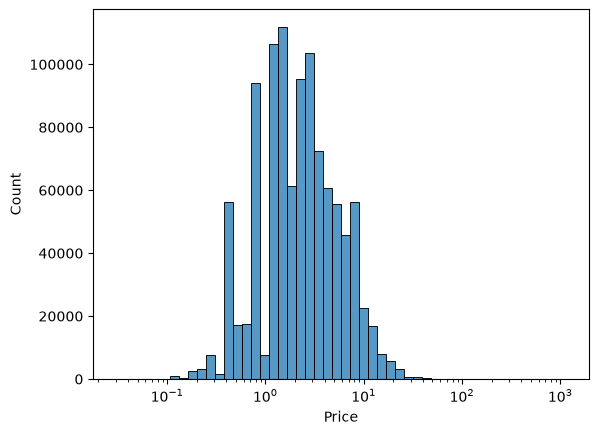

In [45]:
sns.histplot(df['Price'], log_scale = True, bins = 50)

seems like there are still many null-values for customers, will keep them

In [46]:
df['Country'].unique()

<StringArray>
[      'United Kingdom',               'France',            'Australia',
                 'EIRE',              'Germany',             'Portugal',
              'Denmark',          'Netherlands',               'Poland',
      'Channel Islands',                'Spain',               'Cyprus',
              'Belgium',               'Greece',               'Norway',
              'Austria',               'Sweden', 'United Arab Emirates',
              'Finland',                'Italy',          'Switzerland',
                  'USA',                'Japan',          'Unspecified',
                'Malta',              'Bahrain',                  'RSA',
              'Bermuda',            'Hong Kong',            'Singapore',
             'Thailand',               'Israel',            'Lithuania',
              'Nigeria',          'West Indies',              'Lebanon',
                'Korea',               'Brazil',               'Canada',
              'Iceland',         'Sau

<Axes: ylabel='Country'>

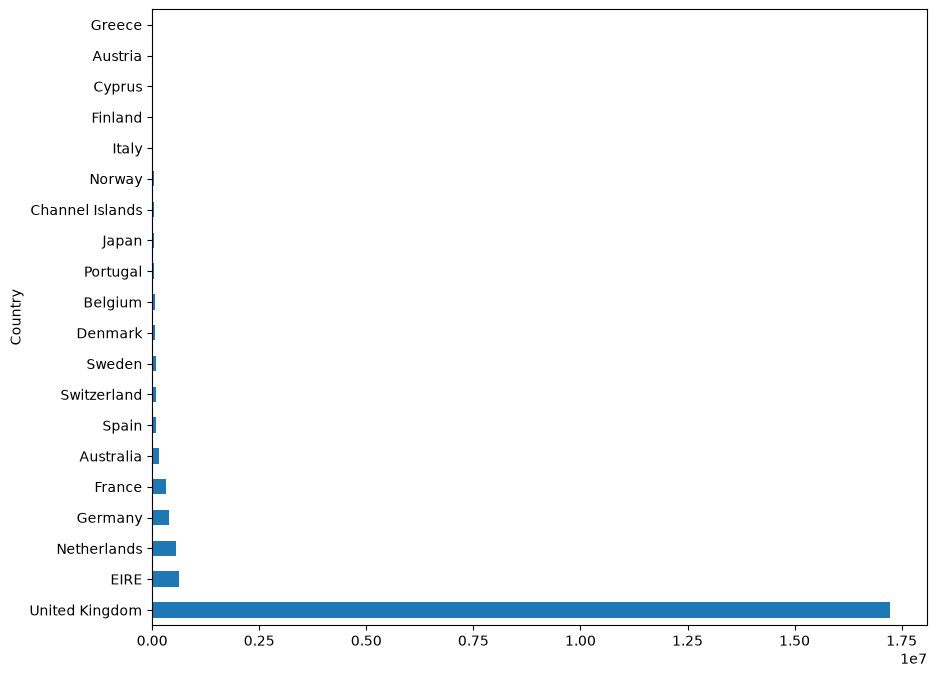

In [50]:
topp10 = df.groupby("Country")["Revenue"].sum().nlargest(20)

topp10.plot.barh(figsize=(10, 8))